In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
adata = sc.read_h5ad("../data/processed/pbmc3k_qc.h5ad") #数据接力
print(adata)
adata.layers["counts"]=adata.X.copy()#adata.X时Anndata的主表达矩阵，此步得到一个独立副本

AnnData object with n_obs × n_vars = 2643 × 13714
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'


In [2]:
sc.pp.normalize_total(adata,
                      target_sum=1e4)#标准化。将所有细胞的表达总量定为10000，再计算每种基因的比例
print(np.asarray(adata.X.sum(axis=1)).ravel()[:5])#把adata.X转化为Numpy的标准数组。便于后续的求和，展平，切片
sc.pp.log1p(adata)#取自然对数
print(adata.X.max())

[10000.    10000.    10000.     9999.998 10000.001]
7.4695992


这一步相当于Seurat中的LogNormalize,在Scanpy里被分为了缩放和取对数两步，可以这么理解：
normalize_total完全去除了测序深度的影响
log化防止后面的Zscore计算时均值和标准差被拉爆，在有巨大变化时小变化也可以显现出来

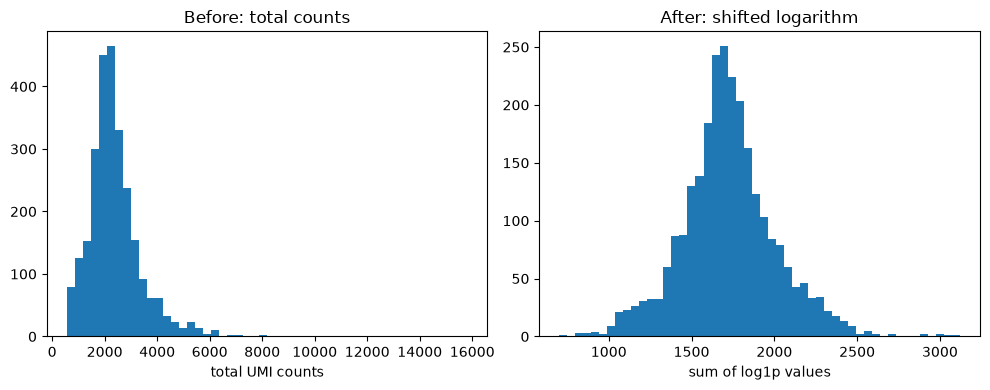

In [3]:
os.makedirs("../results/figures",exist_ok=True)
fig,axes=plt.subplots(1,2,figsize=(10,4))#nrows=1,ncols=2，图片是10X4英寸，如果dpi是300，那就是1000X400像素。解包赋值后左边是总的图，右边是每一个子图
#这一步只是造好了画布和子图的框架，数据在hist函数里填入
axes[0].hist(np.asarray(adata.layers["counts"].sum(axis=1)).ravel(),bins=50)#左图是归一化前，bins=50表示50个柱子
axes[0].set_title("Before: total counts")
axes[0].set_xlabel("total UMI counts")
axes[1].hist(np.asarray(adata.X.sum(axis=1)).ravel(),bins=50)#右图：log1p之后每细胞数值之和，此时adata.X已经是log数据
axes[1].set_title("After: shifted logarithm")#子图标签
axes[1].set_xlabel("sum of log1p values")#X轴标签
plt.tight_layout()#自动调整子图间距
plt.savefig("../results/figures/normalization.png",dpi=300,bbox_inches="tight")
plt.show()
adata.raw=adata

左图：直接比较不同基因的原始计数来寻找高变基因是荒谬的，因为测序深度不同，细胞的UMI总数不同，不同细胞同一基因的UMI数肯定也会有巨大波动。
右图：一个细胞的10000的组成部分各取对数值之后自身求和可以得到其横坐标。这张图除了记录处理外应该没什么意义。可以猜到应该测到的基因种类多，求和的值也会更大。

In [4]:
sc.pp.highly_variable_genes(#筛选高变基因
    adata,
    min_mean=0.0125,#表达均值下限，太低的多半是噪音
    max_mean=3,#表达均值上限，太高的多是管家基因或线粒体基因
    min_disp=0.5#标准化离散度下限
)
print(adata.var[["means","dispersions","dispersions_norm","highly_variable"]].head())
    #mean:平均表达量
    #dispersions:离散度（方差/均值）
    #dispersions_norm:标准化后的离散度
    #highly_variable:高变与否，返回布尔值
print(f"高变基因数量：{adata.var.highly_variable.sum()}")
adata=adata[:,adata.var.highly_variable].copy()

                  means  dispersions  dispersions_norm  highly_variable
index                                                                  
AL627309.1     0.013530     1.432851         -0.619012            False
AP006222.2     0.004687     1.458632         -0.568213            False
RP11-206L10.2  0.005662     1.325461         -0.830613            False
RP11-206L10.9  0.002639     0.859265         -1.749210            False
LINC00115      0.027386     1.457489         -0.570465            False
高变基因数量：1844


In [5]:
sc.pp.scale(adata)#z-score    (x-均值)/标准差
print(adata.X.max())
print(adata.X.min())

46.038362317731135
-1.9500213097163495


A:\pbmc3kP\Lib\functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


这一步相当于Seurat的ScaleData，同样是求Zscore。
后续PCA的操作看绝对方差，但管家基因如果被算入了高变基因，因其基础表达量大，绝对方差也会大，放缩后所有基因的均值都为0，方差都为1。
这一步之后无法再比较基因A和基因B作为高变基因的变化程度了，但是可以作为后续主成分分析的科学数据了。

In [6]:
os.makedirs("../data/processed",exist_ok=True)
adata.write("../data/processed/pbmc3k_normalized_hvg.h5ad")

数据接力

本阶段数据处理后，为PCA降维做好了准备。
头有些晕，总结一下到目前为止对adata进行了哪些改动：
01的sc.datasets.pbmc3k()引入了X（2700细胞× 32738基因）、obs、var
01的var_names_make_unique()把var的重名基因都加了后缀
01的adata.var["mt"]=...使得va新增1列：mt
01的calculate_qc_metrics(inplace=True)使得obs新增3列：n_genes_by_counts、total_counts、pct_counts_mt
01的filter_cells(min_genes=200)使得X行变少、obs行变少
01的filter_genes(min_cells=3)使得X列变少、var行变少
01的adata[pct_counts_mt < 5, :]过滤细胞2700到2643
02的layers["counts"] = adata.X.copy()定义了第一个layer（原始counts的副本）
02的normalize_total()覆盖X：counts→CP10K 值
02的log1p()覆盖X：CP10K→log值
02的adata.raw = adata拷贝raw（全基因的log值）
02的highly_variable_genes()使得var新增4列：means、dispersions、dispersions_norm、highly_variable
02的adata[:, hvg].copy()使得X列变少、var行变少、layers也被一起切、raw 不动
02的scale(max_value=10)覆盖X：log值→z值，且从稀疏矩阵变成稠密矩阵